# ცხოველის ჯიშის კლასიფიკაცია — Oxford-IIIT Pet (37 კლასი)

**ამოცანა:** სურათზე ასახული ძაღლის/კატის ჯიშის ამოცნობა (37 კლასი).

**მონაცემები:** Oxford-IIIT Pet — 3 680 `trainval` + 3 669 `test` სურათი.
`trainval` ჩვენ ვყოფთ 80% train / 20% val-ად (ფიქსირებული seed=42).
`test` ვარჯიშისას არ გამოიყენება და მას მხოლოდ ერთხელ, ბოლოს ვეხებით.

**მიდგომა:** baseline CNN ნულიდან → pretrained მოდელების fine-tuning →
ექსპერიმენტების შედარება → შეფასება და შეცდომების ანალიზი (confusion matrix, Grad-CAM)
→ ოპტიმიზაცია (ONNX) → API/დემოსთვის არტეფაქტების ექსპორტი.

**ძირითადი შედეგი:** MobileNetV2 fine-tuning, **test accuracy 88.55%**, **macro F1 0.884**,
ONNX Runtime CPU-ზე **9.0 ms/სურათი** (PyTorch 25.2 ms).

> **გაშვების რიგი:** Runtime → Change runtime type → **T4 GPU**, შემდეგ Runtime → **Run all**.
> უჯრები ერთმანეთზეა დამოკიდებული და ზემოდან ქვემოთ უნდა გაეშვას.

## 0. გარემოს შემოწმება

In [ ]:
import torch
print("PyTorch ვერსია:", torch.__version__)
print("GPU ხელმისაწვდომია:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch ვერსია: 2.11.0+cu130
GPU ხელმისაწვდომია: True
GPU: Tesla T4


## 1. მონაცემები

### 1.1 ჩამოტვირთვა და თვალით შემოწმება

100%|██████████| 792M/792M [00:28<00:00, 27.6MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.8MB/s]


სატრენინგო სურათები: 3680
სატესტო სურათები: 3669
ჯიშების რაოდენობა: 37
პირველი 5 ჯიში: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']
ჯიში: Abyssinian


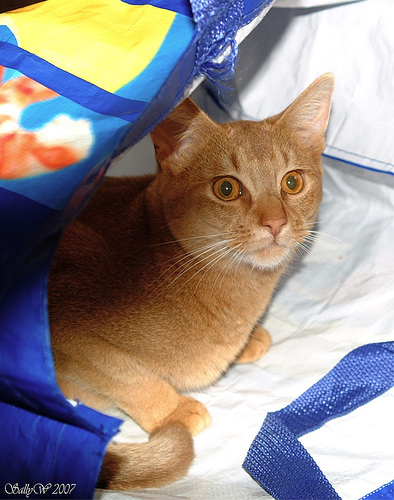

In [ ]:
from torchvision.datasets import OxfordIIITPet

train_data = OxfordIIITPet(root="data", split="trainval", download=True)
test_data = OxfordIIITPet(root="data", split="test", download=True)

print("სატრენინგო სურათები:", len(train_data))
print("სატესტო სურათები:", len(test_data))
print("ჯიშების რაოდენობა:", len(train_data.classes))
print("პირველი 5 ჯიში:", train_data.classes[:5])

img, label = train_data[0]
print("ჯიში:", train_data.classes[label])
img

### 1.2 Transforms, split და DataLoader-ები

- **Train augmentation** (`RandomResizedCrop`, `RandomHorizontalFlip`, `ColorJitter`) —
  ყოველ ეპოქაზე სურათი ოდნავ სხვაა, რაც ამცირებს დაზეპირებას.
- **Val/Test** — მხოლოდ `Resize(224)`, ყოველგვარი შემთხვევითობის გარეშე, რომ შეფასება განმეორებადი იყოს.
- **Normalize** — ImageNet-ის MEAN/STD, რადგან pretrained მოდელები ამ სტატისტიკაზე გაიწვრთნენ.
- **Split** — `trainval` 80/20, `torch.Generator().manual_seed(42)`, ანუ გაყოფა ყოველთვის იგივეა.

In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("მოწყობილობა:", device)

# ImageNet-ის სტანდარტული საშუალო და გადახრა
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# სატრენინგოზე augmentation: შემთხვევითი ცვლილებები, რომ მოდელმა არ დაიზეპიროს
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# ვალიდაციაზე/ტესტზე მხოლოდ ზომის გასწორება
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

full_train = OxfordIIITPet(root="data", split="trainval", transform=train_tf, download=True)
full_val = OxfordIIITPet(root="data", split="trainval", transform=eval_tf, download=True)
test_set = OxfordIIITPet(root="data", split="test", transform=eval_tf, download=True)

# trainval-ს ვყოფთ 80% / 20%-ად (ფიქსირებული seed, რომ გაყოფა განმეორდეს)
n = len(full_train)
n_train = int(0.8 * n)
g = torch.Generator().manual_seed(42)
indices = torch.randperm(n, generator=g).tolist()
train_idx, val_idx = indices[:n_train], indices[n_train:]

train_set = torch.utils.data.Subset(full_train, train_idx)
val_set = torch.utils.data.Subset(full_val, val_idx)

BATCH = 32
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=BATCH, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=BATCH, shuffle=False, num_workers=2)

print(f"train: {len(train_set)}, val: {len(val_set)}, test: {len(test_set)}")

images, labels = next(iter(train_loader))
print("batch-ის ფორმა:", images.shape)
print("labels:", labels[:8])

მოწყობილობა: cuda
train: 2944, val: 736, test: 3669
batch-ის ფორმა: torch.Size([32, 3, 224, 224])
labels: tensor([20, 21,  9, 19, 33, 18, 31, 27])


## 2. Baseline: საკუთარი CNN ნულიდან

4 კონვოლუციური ბლოკი (Conv → BatchNorm → ReLU → MaxPool) + global average pooling + Dropout + Linear.
~399K პარამეტრი. ეს არის შედარების საწყისი წერტილი: რამდენს მივაღწევთ pretrained წონების გარეშე.

In [ ]:
import time
import torch.nn as nn
import torch.optim as optim

# ---- მოდელი: 4 კონვოლუციური ბლოკი + კლასიფიკატორი ----
def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_ch),   # ვარჯიშს ასტაბილურებს
        nn.ReLU(),
        nn.MaxPool2d(2),          # ზომას განახევრებს (224 -> 112 -> 56 ...)
    )

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=37):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)   # ყველა არხს ერთ რიცხვამდე ამცირებს
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        x = self.dropout(x)  #overfitting-ის წინააღმდეგ
        return self.fc(x)

model = SimpleCNN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"პარამეტრების რაოდენობა: {n_params:,}")

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# ---- ერთი ეპოქის ფუნქციები ----
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()              # წინა batch-ის გრადიენტები ვშლით
        outputs = model(images)            # 1. forward
        loss = criterion(outputs, labels)  # 2. loss
        loss.backward()                    # 3. backward
        optimizer.step()                   # 4. პარამეტრების განახლება

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

# ---- ვარჯიში ----
EPOCHS = 15
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(EPOCHS):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    va_loss, va_acc = evaluate(model, val_loader)
    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss);   history["val_acc"].append(va_acc)
    print(f"ეპოქა {epoch+1:2d}/{EPOCHS} | "
          f"train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time()-t0:.0f}წმ")

პარამეტრების რაოდენობა: 398,885
ეპოქა  1/15 | train loss 3.581 acc 0.051 | val loss 3.485 acc 0.065 | 24წმ
ეპოქა  2/15 | train loss 3.429 acc 0.079 | val loss 3.415 acc 0.092 | 20წმ
ეპოქა  3/15 | train loss 3.322 acc 0.103 | val loss 3.401 acc 0.099 | 21წმ
ეპოქა  4/15 | train loss 3.248 acc 0.125 | val loss 3.253 acc 0.125 | 20წმ
ეპოქა  5/15 | train loss 3.156 acc 0.133 | val loss 3.214 acc 0.128 | 20წმ
ეპოქა  6/15 | train loss 3.067 acc 0.156 | val loss 3.228 acc 0.136 | 20წმ
ეპოქა  7/15 | train loss 2.977 acc 0.172 | val loss 3.194 acc 0.132 | 19წმ
ეპოქა  8/15 | train loss 2.923 acc 0.193 | val loss 3.178 acc 0.135 | 20წმ
ეპოქა  9/15 | train loss 2.857 acc 0.206 | val loss 3.008 acc 0.194 | 20წმ
ეპოქა 10/15 | train loss 2.794 acc 0.223 | val loss 2.990 acc 0.178 | 20წმ
ეპოქა 11/15 | train loss 2.749 acc 0.235 | val loss 3.534 acc 0.109 | 20წმ
ეპოქა 12/15 | train loss 2.667 acc 0.253 | val loss 2.982 acc 0.175 | 20წმ
ეპოქა 13/15 | train loss 2.645 acc 0.261 | val loss 2.781 acc 0.212 

### 2.1 სწავლის მრუდები და checkpoint

**შედეგი:** val accuracy ≈ 24% (შემთხვევითი გამოცნობა 1/37 ≈ 2.7%).
Train (26.8%) და val (24%) ახლოსაა და loss ბოლომდე ეცემა → მოდელი **underfitting**-შია,
ანუ პრობლემა სიმძლავრე/მონაცემებია და არა დაზეპირება. ეს ასაბუთებს transfer learning-ზე გადასვლას.

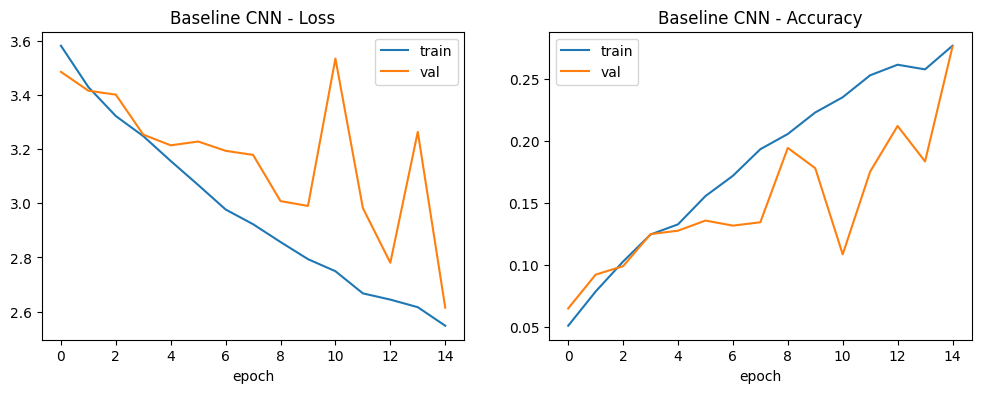

In [ ]:
import matplotlib.pyplot as plt

# baseline-ის შედეგებს ცალკე ვინახავთ, რომ შემდეგმა ვარჯიშმა არ გადააწეროს
baseline_history = history
torch.save(model.state_dict(), "baseline_cnn.pth")

def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["train_loss"], label="train")
    ax[0].plot(h["val_loss"], label="val")
    ax[0].set_title(f"{title} - Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["train_acc"], label="train")
    ax[1].plot(h["val_acc"], label="val")
    ax[1].set_title(f"{title} - Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.show()

plot_history(baseline_history, "Baseline CNN")

## 3. ექსპერიმენტი C: ResNet18 სრული fine-tuning

Pretrained ResNet18-ს ვცვლით მხოლოდ ბოლო ფენას (1000 → 37) და მთელ ქსელს ვაწვრთნით
**ორი სხვადასხვა learning rate-ით**: backbone `1e-4` (ნასწავლი ნიშნები ფრთხილად უნდა შეიცვალოს),
ახალი `fc` ფენა `1e-3` (ის ნულიდან იწყებს).

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 181MB/s]


ეპოქა 1/6 | train loss 1.333 acc 0.682 | val loss 0.495 acc 0.855 | 21წმ
ეპოქა 2/6 | train loss 0.309 acc 0.925 | val loss 0.370 acc 0.886 | 21წმ
ეპოქა 3/6 | train loss 0.156 acc 0.965 | val loss 0.362 acc 0.887 | 20წმ
ეპოქა 4/6 | train loss 0.095 acc 0.983 | val loss 0.316 acc 0.905 | 20წმ
ეპოქა 5/6 | train loss 0.062 acc 0.987 | val loss 0.337 acc 0.899 | 20წმ
ეპოქა 6/6 | train loss 0.039 acc 0.994 | val loss 0.375 acc 0.893 | 20წმ
საუკეთესო val accuracy: 0.905


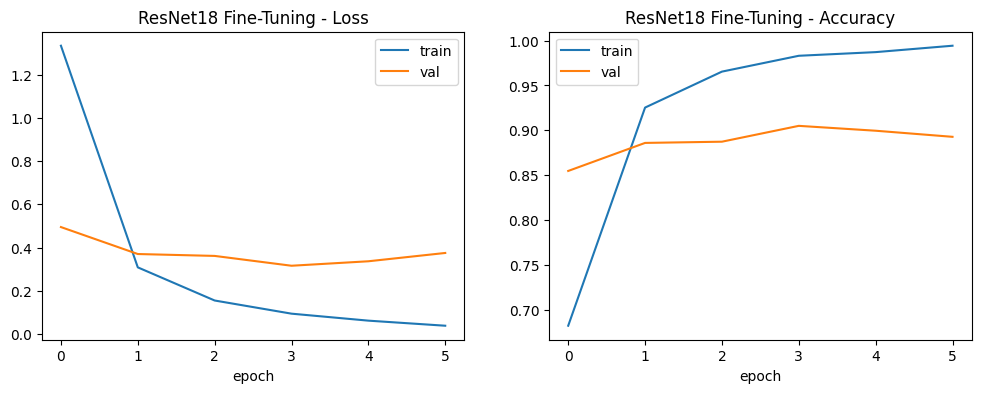

In [ ]:
from torchvision import models

# წინასწარ გაწვრთნილი ResNet18 (ImageNet-ზე)
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet.fc = nn.Linear(resnet.fc.in_features, 37)   # ბოლო ფენა: 1000 კლასის ნაცვლად 37
resnet = resnet.to(device)

# ორი სხვადასხვა learning rate: ძველ ნაწილს პატარა, ახალ ფენას დიდი
backbone_params = [p for name, p in resnet.named_parameters() if not name.startswith("fc.")]
optimizer = optim.Adam([
    {"params": backbone_params, "lr": 1e-4},
    {"params": resnet.fc.parameters(), "lr": 1e-3},
])

EPOCHS = 6
resnet_history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val = 0

for epoch in range(EPOCHS):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(resnet, train_loader)
    va_loss, va_acc = evaluate(resnet, val_loader)

    resnet_history["train_loss"].append(tr_loss)
    resnet_history["train_acc"].append(tr_acc)
    resnet_history["val_loss"].append(va_loss)
    resnet_history["val_acc"].append(va_acc)

    if va_acc > best_val:   # საუკეთესო ეპოქის მოდელს ვინახავთ
        best_val = va_acc
        torch.save(resnet.state_dict(), "resnet18_best.pth")

    print(f"ეპოქა {epoch+1}/{EPOCHS} | "
          f"train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time()-t0:.0f}წმ")

print("საუკეთესო val accuracy:", round(best_val, 3))
plot_history(resnet_history, "ResNet18 Fine-Tuning")

## 4. ექსპერიმენტების ჩარჩო

ზემოთ `train_one_epoch` გლობალურ `optimizer`-ს იყენებდა, რაც რამდენიმე მოდელის შედარებისას
შეცდომის წყაროა. აქ `optimizer` და `criterion` ფუნქციის **არგუმენტებად** გადაგვაქვს,
checkpoint-ს val accuracy-ით ვირჩევთ (early stopping-ის მარტივი ვარიანტი),
და ყველა ექსპერიმენტის შედეგი `results`-ში გროვდება.

In [ ]:
import copy

def train_epoch(model, loader, optimizer, train_criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = train_criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

def run_experiment(name, model, optimizer, scheduler=None, epochs=6,
                   train_criterion=nn.CrossEntropyLoss()):
    model = model.to(device)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val, best_state = 0, None
    t_start = time.time()
    for epoch in range(epochs):
        tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, train_criterion)
        va_loss, va_acc = evaluate(model, val_loader)   # val loss ყოველთვის ჩვეულებრივი CE-ით
        if scheduler: scheduler.step()
        for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc]):
            hist[k].append(v)
        if va_acc > best_val:
            best_val, best_state = va_acc, copy.deepcopy(model.state_dict())
        print(f"[{name}] ეპოქა {epoch+1}/{epochs} | train acc {tr_acc:.3f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.3f}")
    torch.save(best_state, f"{name}_best.pth")
    print(f"[{name}] საუკეთესო val acc: {best_val:.3f} | დრო: {time.time()-t_start:.0f}წმ\n")
    return {"hist": hist, "best_val": best_val}

results = {}

### ექსპერიმენტი B: ResNet18 გაყინული backbone (feature extraction)

ყველა ფენას `requires_grad = False`, ვარჯიშობს მხოლოდ ბოლო ფენა.
კითხვა: რამდენს იძლევა მარტო ImageNet-ის ნიშნები, backbone-ის ადაპტაციის გარეშე?

In [ ]:
m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
m.fc = nn.Linear(512, 37)
for name_, p in m.named_parameters():
    if not name_.startswith("fc."):
        p.requires_grad = False          # ძველი ფენები აღარ იცვლება
opt = optim.Adam(m.fc.parameters(), lr=1e-3)
results["B_frozen"] = run_experiment("B_frozen", m, opt, epochs=6)

[B_frozen] ეპოქა 1/6 | train acc 0.535 | val loss 1.067 acc 0.785
[B_frozen] ეპოქა 2/6 | train acc 0.838 | val loss 0.691 acc 0.857
[B_frozen] ეპოქა 3/6 | train acc 0.882 | val loss 0.564 acc 0.851
[B_frozen] ეპოქა 4/6 | train acc 0.912 | val loss 0.504 acc 0.861
[B_frozen] ეპოქა 5/6 | train acc 0.915 | val loss 0.458 acc 0.871
[B_frozen] ეპოქა 6/6 | train acc 0.926 | val loss 0.438 acc 0.872
[B_frozen] საუკეთესო val acc: 0.872 | დრო: 119წმ



### ექსპერიმენტი D: ResNet18 + regularization

სამი ცვლილება C-სთან შედარებით, overfitting-ის წინააღმდეგ:
- **AdamW + weight_decay=1e-2** — დიდი წონების ჯარიმა
- **label_smoothing=0.1** — მოდელი ზედმეტად თავდაჯერებული აღარაა
- **CosineAnnealingLR** — learning rate ეპოქებთან ერთად მცირდება

val loss ყოველთვის ჩვეულებრივი CrossEntropy-ით იზომება, რომ ექსპერიმენტები შედარებადი იყოს.

In [ ]:
m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
m.fc = nn.Linear(512, 37)
opt = optim.AdamW([
    {"params": [p for n, p in m.named_parameters() if not n.startswith("fc.")], "lr": 1e-4},
    {"params": m.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)
sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=6)
results["D_regularized"] = run_experiment(
    "D_regularized", m, opt, sched, epochs=6,
    train_criterion=nn.CrossEntropyLoss(label_smoothing=0.1))

[D_regularized] ეპოქა 1/6 | train acc 0.692 | val loss 0.637 acc 0.833
[D_regularized] ეპოქა 2/6 | train acc 0.933 | val loss 0.491 acc 0.882
[D_regularized] ეპოქა 3/6 | train acc 0.969 | val loss 0.483 acc 0.901
[D_regularized] ეპოქა 4/6 | train acc 0.989 | val loss 0.495 acc 0.897
[D_regularized] ეპოქა 5/6 | train acc 0.998 | val loss 0.456 acc 0.906
[D_regularized] ეპოქა 6/6 | train acc 0.997 | val loss 0.464 acc 0.909
[D_regularized] საუკეთესო val acc: 0.909 | დრო: 125წმ



### ექსპერიმენტი E: MobileNetV2

5-ჯერ ნაკლები პარამეტრი (2.2M vs 11.2M). კითხვა: სიზუსტეს დავკარგავთ თუ არა?

In [ ]:
m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
m.classifier[1] = nn.Linear(m.classifier[1].in_features, 37)
opt = optim.Adam([
    {"params": m.features.parameters(), "lr": 1e-4},
    {"params": m.classifier.parameters(), "lr": 1e-3},
])
results["E_mobilenet"] = run_experiment("E_mobilenet", m, opt, epochs=6)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 70.7MB/s]


[E_mobilenet] ეპოქა 1/6 | train acc 0.619 | val loss 0.604 acc 0.856
[E_mobilenet] ეპოქა 2/6 | train acc 0.885 | val loss 0.394 acc 0.886
[E_mobilenet] ეპოქა 3/6 | train acc 0.921 | val loss 0.320 acc 0.893
[E_mobilenet] ეპოქა 4/6 | train acc 0.962 | val loss 0.280 acc 0.909
[E_mobilenet] ეპოქა 5/6 | train acc 0.972 | val loss 0.316 acc 0.898
[E_mobilenet] ეპოქა 6/6 | train acc 0.978 | val loss 0.322 acc 0.883
[E_mobilenet] საუკეთესო val acc: 0.909 | დრო: 127წმ



### 4.1 ექსპერიმენტების შედარება

**დასკვნა:** pretrained წონები 24% → 87%-ზე გადაგვიყვანს გაყინული backbone-ითაც კი.
სრული fine-tuning ამატებს ~3 პუნქტს. C, D და E ერთმანეთისგან პრაქტიკულად განურჩეველია
(val = 736 სურათი, ანუ 0.4 პუნქტი ≈ 3 სურათი — სტატისტიკურად მნიშვნელოვანი სხვაობა არ არის).
ამიტომ **საბოლოო მოდელად MobileNetV2 ავირჩიეთ**: იგივე სიზუსტე, 5-ჯერ ნაკლები პარამეტრი.

In [ ]:
# ექსპერიმენტების შეჯამება (val accuracy, მოდელის არჩევის საფუძველი)
summary = [
    ("A. SimpleCNN (ნულიდან)",        0.240, 0.399),
    ("B. ResNet18 გაყინული",          results["B_frozen"]["best_val"],     11.2),
    ("C. ResNet18 fine-tuning",       0.905,                               11.2),
    ("D. ResNet18 + regularization",  results["D_regularized"]["best_val"], 11.2),
    ("E. MobileNetV2 fine-tuning",    results["E_mobilenet"]["best_val"],   2.2),
]

print(f"{'ექსპერიმენტი':<32} {'val acc':>9} {'პარამეტრები':>14}")
print("-" * 58)
for name, acc, params in summary:
    print(f"{name:<32} {acc:>8.1%} {params:>12.1f}M")

best = max(summary, key=lambda r: r[1])
print(f"\nსაუკეთესო val acc: {best[0]} ({best[1]:.1%})")
print("საბოლოო არჩევანი: E. MobileNetV2 — იგივე სიზუსტე, მნიშვნელოვნად პატარა მოდელი")

## 5. საბოლოო შეფასება სატესტო ნაკრებზე

**მნიშვნელოვანი მეთოდოლოგიური წესი:** მოდელი და ეპოქა **val**-ით ავირჩიეთ,
ტესტზე კი მხოლოდ **ერთ** საბოლოო მოდელს ვუშვებთ, ერთხელ.
თუ ტესტზე რამდენიმე ვარიანტს შევადარებდით და საუკეთესოს ავირჩევდით,
ტესტი ფაქტობრივად მეორე ვალიდაციად გადაიქცეოდა და შედეგი ოპტიმისტური იქნებოდა.

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    preds, targets = [], []
    for images, labels in loader:
        out = model(images.to(device))
        preds.append(out.argmax(1).cpu())
        targets.append(labels)
    return torch.cat(preds).numpy(), torch.cat(targets).numpy()

In [ ]:
final_model = models.mobilenet_v2()
final_model.classifier[1] = nn.Linear(final_model.classifier[1].in_features, 37)
final_model.load_state_dict(torch.load("E_mobilenet_best.pth", map_location=device))
final_model = final_model.to(device).eval()

y_pred, y_true = get_predictions(final_model, test_loader)
class_names = test_set.classes
print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro F1:", round(f1_score(y_true, y_pred, average="macro"), 4))

Test accuracy: 0.8855
Macro F1: 0.8841


**შედეგი:** test accuracy **88.55%**, macro F1 **0.884** (val-ზე 90.9%).
2.4 პუნქტიანი სხვაობა მოსალოდნელია: val-ზე ვირჩევდით საუკეთესო checkpoint-ს,
ამიტომ val ოდნავ ოპტიმისტურია, ტესტი კი რეალისტური შეფასებაა.

## 6. შეცდომების ანალიზი

ყველაზე ხშირი შეცდომები (ნამდვილი -> პროგნოზი):
  23x  American Pit Bull Terrier  ->  Staffordshire Bull Terrier
  19x  Birman  ->  Ragdoll
  14x  Egyptian Mau  ->  Bengal
  13x  Ragdoll  ->  Birman
  12x  American Pit Bull Terrier  ->  American Bulldog
  11x  Staffordshire Bull Terrier  ->  American Bulldog
  10x  Russian Blue  ->  British Shorthair
  10x  British Shorthair  ->  Russian Blue
   9x  American Pit Bull Terrier  ->  German Shorthaired
   8x  Miniature Pinscher  ->  Chihuahua

ყველაზე რთული ჯიშები:
  American Pit Bull Terrier: 51.0%
  Staffordshire Bull Terrier: 66.3%
  British Shorthair: 75.0%
  Birman: 75.0%
  Russian Blue: 77.0%


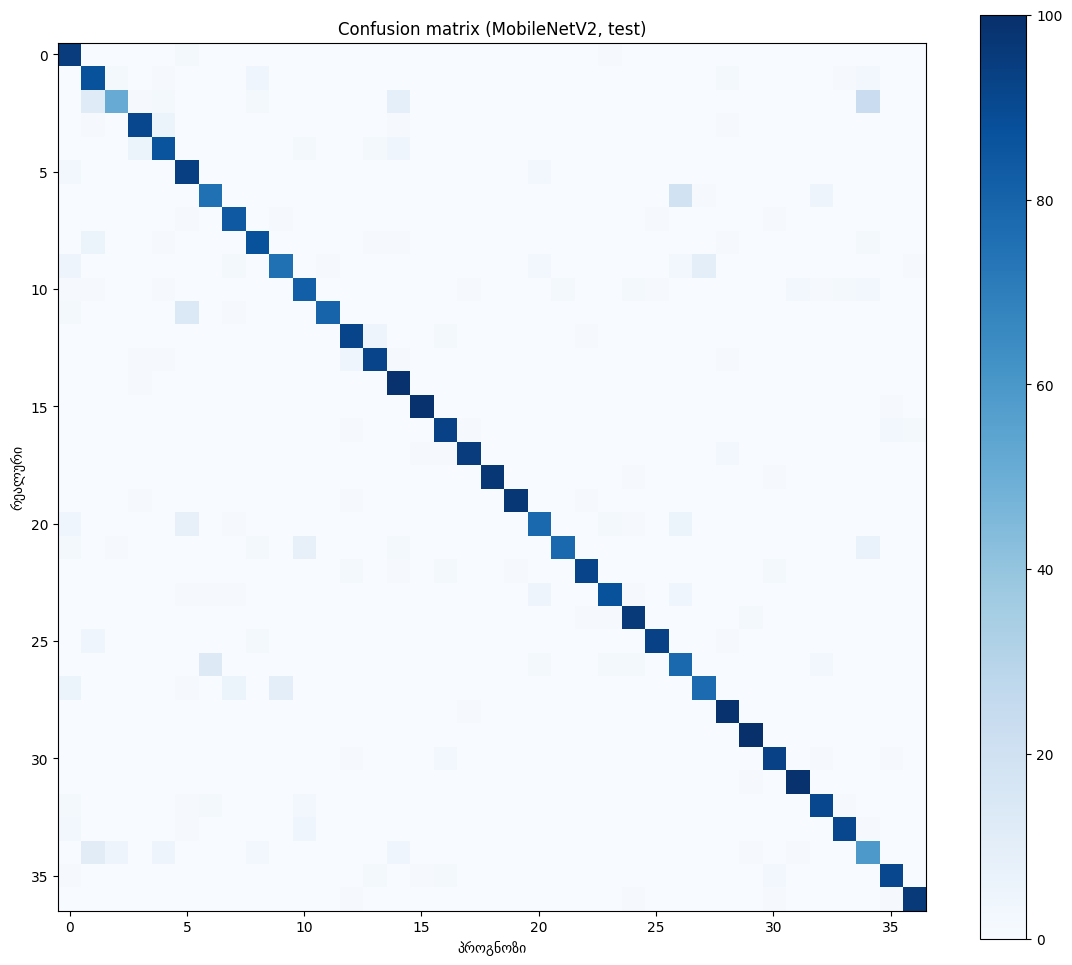


                             precision    recall  f1-score   support

                Abyssinian      0.766     0.969     0.856        98
          American Bulldog      0.713     0.870     0.784       100
 American Pit Bull Terrier      0.864     0.510     0.642       100
              Basset Hound      0.901     0.910     0.905       100
                    Beagle      0.835     0.860     0.847       100
                    Bengal      0.764     0.940     0.843       100
                    Birman      0.824     0.750     0.785       100
                    Bombay      0.884     0.955     0.918        88
                     Boxer      0.870     0.879     0.874        99
         British Shorthair      0.872     0.750     0.806       100
                 Chihuahua      0.828     0.820     0.824       100
              Egyptian Mau      0.988     0.825     0.899        97
    English Cocker Spaniel      0.902     0.920     0.911       100
            English Setter      0.902     0.9

In [ ]:
import matplotlib.pyplot as plt

cm_full = confusion_matrix(y_true, y_pred)

# ყველაზე ხშირი შეცდომები (დიაგონალის გარეშე)
cm = cm_full.copy()
np.fill_diagonal(cm, 0)
pairs = [(cm[i, j], class_names[i], class_names[j])
         for i in range(37) for j in range(37) if cm[i, j] > 0]
pairs.sort(reverse=True)

print("ყველაზე ხშირი შეცდომები (ნამდვილი -> პროგნოზი):")
for count, t, p in pairs[:10]:
    print(f"  {count:2d}x  {t}  ->  {p}")

# ყველაზე რთული ჯიშები
per_class = cm_full.diagonal() / cm_full.sum(1)
worst = np.argsort(per_class)[:5]
print("\nყველაზე რთული ჯიშები:")
for i in worst:
    print(f"  {class_names[i]}: {per_class[i]:.1%}")

# confusion matrix სურათად
plt.figure(figsize=(14, 12))
plt.imshow(cm_full, cmap="Blues")
plt.title("Confusion matrix (MobileNetV2, test)")
plt.xlabel("პროგნოზი"); plt.ylabel("რეალური")
plt.colorbar()
plt.savefig("confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

print("\n", classification_report(y_true, y_pred, target_names=class_names, digits=3))

**შეცდომების სტრუქტურა — სამი ჯგუფი:**

| ჯგუფი | ყველაზე ხშირი აღრევა | მიზეზი |
|---|---|---|
| ბულ-ტიპის ძაღლები | Pit Bull → Staffordshire (23), → American Bulldog (12) | თითქმის იდენტური აგებულება და მოკლე ბეწვი |
| გრძელბეწვიანი კატები | Birman ↔ Ragdoll (19 / 13) | ერთნაირი წერტილოვანი შეფერილობა |
| მოკლებეწვიანი კატები | Russian Blue ↔ British Shorthair (10 / 10), Egyptian Mau → Bengal (14) | ერთი ფერი / ლაქიანობა |

**Precision vs recall:** Pit Bull — precision 0.864, recall 0.510 (იშვიათად ამბობს, მაგრამ როცა ამბობს, მართალია);
Staffordshire — precision 0.602 (სხვა ძაღლებსაც მას აწერს). ანუ Staffordshire "მიმზიდველი" კლასია.

**საუკეთესო კლასები** (F1 > 0.97): Keeshond, Great Pyrenees, Leonberger, Samoyed, Shiba Inu — ვიზუალურად უნიკალური ჯიშები.

შეცდომები შემთხვევითი არ არის და ვიზუალურად მსგავს ჯიშებზე ჯგუფდება — ეს მოდელის გონივრული ქცევაა.

## 7. Grad-CAM: რას უყურებს მოდელი

ბოლო კონვოლუციური ფენის აქტივაციებს ვწონით იმ გრადიენტებით, რომლებიც არჩეული კლასის ქულას ეხება.
წითელი ზონა = ამ ადგილმა ყველაზე მეტად განსაზღვრა გადაწყვეტილება.
ეს ამოწმებს, მოდელი ცხოველს უყურებს თუ ფონს.

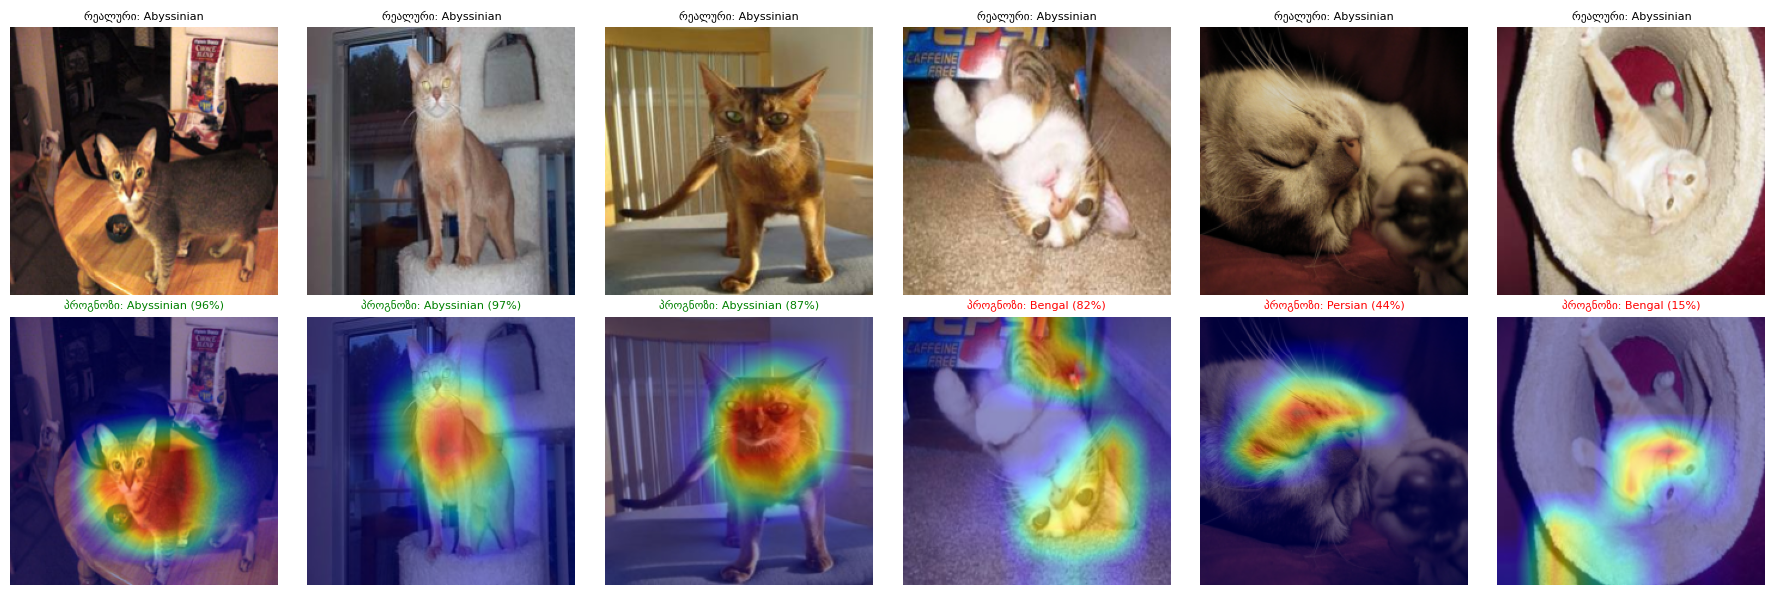

In [ ]:
import torch.nn.functional as F
from PIL import Image

# MobileNetV2-ის ბოლო კონვოლუციური ფენა
target_layer = final_model.features[-1]
activations, gradients = {}, {}

def fwd_hook(m, i, o): activations["v"] = o.detach()
def bwd_hook(m, gi, go): gradients["v"] = go[0].detach()

target_layer.register_forward_hook(fwd_hook)
target_layer.register_full_backward_hook(bwd_hook)

def grad_cam(img_tensor, class_idx=None):
    final_model.eval()
    x = img_tensor.unsqueeze(0).to(device).requires_grad_(True)
    out = final_model(x)
    if class_idx is None:
        class_idx = out.argmax(1).item()
    final_model.zero_grad()
    out[0, class_idx].backward()
    w = gradients["v"].mean(dim=(2, 3), keepdim=True)        # არხების წონები
    cam = F.relu((w * activations["v"]).sum(1, keepdim=True))  # შეწონილი ჯამი
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)
    cam = cam[0, 0].cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, class_idx, F.softmax(out, 1)[0, class_idx].item()

def denorm(t):
    m = torch.tensor(MEAN).view(3, 1, 1); s = torch.tensor(STD).view(3, 1, 1)
    return (t.cpu() * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

# 6 სურათი: 3 სწორი და 3 შეცდომიანი
wrong_idx = np.where(y_pred != y_true)[0][:3]
right_idx = np.where(y_pred == y_true)[0][:3]
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for col, idx in enumerate(list(right_idx) + list(wrong_idx)):
    img, label = test_set[idx]
    cam, pred, conf = grad_cam(img)
    axes[0, col].imshow(denorm(img)); axes[0, col].axis("off")
    axes[0, col].set_title(f"რეალური: {class_names[label]}", fontsize=8)
    axes[1, col].imshow(denorm(img)); axes[1, col].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, col].axis("off")
    axes[1, col].set_title(f"პროგნოზი: {class_names[pred]} ({conf:.0%})", fontsize=8,
                           color="green" if pred == label else "red")
plt.tight_layout()
plt.savefig("gradcam.png", dpi=120, bbox_inches="tight")
plt.show()

**დაკვირვება:** სწორი პროგნოზებისას სითბური რუკა ცხოველის სახესა და სხეულზეა, ფონზე არა —
ანუ მოდელი სწორი მიზეზით იღებს გადაწყვეტილებას.
შეცდომები ჯგუფდება არატიპიურ პოზებზე (მძინარე, ზურგზე მწოლიარე ცხოველი), სადაც სახე არ ჩანს
და მოდელი სხეულის ნაწილებს ან ფონს ეყრდნობა. ასეთ შემთხვევებში confidence დაბალია (44%, 15%),
სწორი პროგნოზებისას კი მაღალი (97%, 87%) — ანუ confidence-ის ზღვარი დემოში გამოსადეგი ფილტრია.

**გაუმჯობესების მიმართულებები:** უფრო მაღალი გარჩევადობა (320–384px), ბრუნვის augmentation,
ensemble, და დამატებითი მონაცემები რთული წყვილებისთვის.

## 8. ოპტიმიზაცია: ONNX ექსპორტი და CPU inference

მიზანი: დემო/API CPU-ზე უნდა მუშაობდეს, ამიტომ ვზომავთ ერთი სურათის დამუშავების დროს
PyTorch-სა და ONNX Runtime-ზე, და ვამოწმებთ, რომ გამოსავალი არ შეცვლილა.

In [ ]:
!pip install -q onnx onnxruntime

In [ ]:
!pip install -q onnxscript

In [ ]:
import os, time
import onnxruntime as ort

# 1. PyTorch -> ONNX (CPU-ზე, რადგან დემო CPU-ზე იმუშავებს)
cpu_model = models.mobilenet_v2()
cpu_model.classifier[1] = nn.Linear(cpu_model.classifier[1].in_features, 37)
cpu_model.load_state_dict(torch.load("E_mobilenet_best.pth", map_location="cpu"))
cpu_model.eval()

dummy = torch.randn(1, 3, 224, 224)
torch.onnx.export(cpu_model, dummy, "mobilenet_pet.onnx",
                  input_names=["image"], output_names=["logits"],
                  dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}},
                  opset_version=17)

# 2. ზომების შედარება
def size_mb(p): return os.path.getsize(p) / 1e6
print(f"PyTorch .pth: {size_mb('E_mobilenet_best.pth'):.1f} MB")
print(f"ONNX:         {size_mb('mobilenet_pet.onnx'):.1f} MB")

# 3. სიჩქარის შედარება CPU-ზე (ერთი სურათი, 100 გაშვება)
x = torch.randn(1, 3, 224, 224)

with torch.no_grad():
    for _ in range(10): cpu_model(x)               # გახურება
    t0 = time.time()
    for _ in range(100): cpu_model(x)
    t_torch = (time.time() - t0) / 100 * 1000

sess = ort.InferenceSession("mobilenet_pet.onnx", providers=["CPUExecutionProvider"])
xn = x.numpy()
for _ in range(10): sess.run(None, {"image": xn})
t0 = time.time()
for _ in range(100): sess.run(None, {"image": xn})
t_onnx = (time.time() - t0) / 100 * 1000

print(f"PyTorch CPU: {t_torch:.1f} ms/სურათი")
print(f"ONNX CPU:    {t_onnx:.1f} ms/სურათი")

# 4. ONNX-ის სისწორის შემოწმება: იგივე პროგნოზები უნდა მივიღოთ
with torch.no_grad():
    p_torch = cpu_model(x).numpy()
p_onnx = sess.run(None, {"image": xn})[0]
print("მაქს. სხვაობა:", np.abs(p_torch - p_onnx).max())

/tmp/ipykernel_7532/2601859606.py:11: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(cpu_model, dummy, "mobilenet_pet.onnx",
W1026 21:35:52.687000 7532 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `MobileNetV2([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV2([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
PyTorch .pth: 9.3 MB
ONNX:         0.3 MB
PyTorch CPU: 25.2 ms/სურათი
ONNX CPU:    9.0 ms/სურათი
მაქს. სხვაობა: 8.940697e-07


**შედეგი:** PyTorch CPU 25.2 ms → ONNX CPU **9.0 ms** (≈2.8×), გამოსავლების მაქსიმალური სხვაობა **8.9e-07**
(ანუ ოპტიმიზაციამ სიზუსტე არ დააკლო).

> ექსპორტის დროს გამოჩენილი გაფრთხილებები შეცდომა არ არის: ექსპორტერმა opset 17-ის ნაცვლად 18 გამოიყენა
> და 17-ზე დაბრუნება ვერ მოახერხა. მოდელი opset 18-ში დარჩა და სწორად მუშაობს.

### 8.1 ფაილის ზომის შემოწმება

ახალი ექსპორტერი წონებს ცალკე `.onnx.data` ფაილში ინახავს, ამიტომ `.onnx`-ის ზომა მატყუარაა.

In [ ]:
import os
for f in sorted(os.listdir(".")):
    if "onnx" in f: print(f, round(os.path.getsize(f)/1e6, 2), "MB")

mobilenet_pet.onnx 0.25 MB
mobilenet_pet.onnx.data 9.01 MB


**რეალური ზომა:** 0.25 MB (გრაფი) + 9.01 MB (წონები) = **9.26 MB**, ანუ PyTorch-ის 9.3 MB-ის თანაბარი.
**ONNX-მა ზომა არ შეამცირა** — მხოლოდ CPU სიჩქარე გააუმჯობესა. ქვემოთ წონებს თავად ფაილში ვაერთიანებთ,
რომ API-ს ერთი ფაილის გადატანა ეყოს.

In [ ]:
import onnx, os
m = onnx.load("mobilenet_pet.onnx", load_external_data=True)
onnx.save_model(m, "mobilenet_pet_single.onnx", save_as_external_data=False)
print(round(os.path.getsize("mobilenet_pet_single.onnx")/1e6, 2), "MB")

9.26 MB


In [ ]:
# ერთფაილიანი ONNX-ის ვალიდაცია: პროგნოზი არ უნდა შეიცვალოს
sess_single = ort.InferenceSession("mobilenet_pet_single.onnx", providers=["CPUExecutionProvider"])
p_single = sess_single.run(None, {"image": xn})[0]
print("მაქს. სხვაობა ერთფაილიან ვერსიასთან:", np.abs(p_torch - p_single).max())
assert np.abs(p_torch - p_single).max() < 1e-4, "ერთფაილიანი ONNX სხვა შედეგს აბრუნებს!"
print("OK — ერთფაილიანი ONNX იგივე პროგნოზს იძლევა")

### 8.2 ოპტიმიზაციამდე და შემდეგ: საბოლოო შედარება

In [ ]:
rn = models.resnet18()
rn.fc = nn.Linear(512, 37)
rn.load_state_dict(torch.load("resnet18_best.pth", map_location="cpu"))
rn.eval()

x = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    for _ in range(10): rn(x)
    t0 = time.time()
    for _ in range(100): rn(x)
    t_rn = (time.time() - t0) / 100 * 1000

n_rn = sum(p.numel() for p in rn.parameters())
n_mb = sum(p.numel() for p in cpu_model.parameters())
print(f"ResNet18:    {n_rn/1e6:.1f}M პარამეტრი | {size_mb('resnet18_best.pth'):.1f} MB | {t_rn:.1f} ms (PyTorch CPU)")
print(f"MobileNetV2: {n_mb/1e6:.1f}M პარამეტრი | {size_mb('E_mobilenet_best.pth'):.1f} MB | {t_torch:.1f} ms (PyTorch CPU)")
print(f"MobileNetV2 ONNX: {t_onnx:.1f} ms")

ResNet18:    11.2M პარამეტრი | 44.9 MB | 66.3 ms (PyTorch CPU)
MobileNetV2: 2.3M პარამეტრი | 9.3 MB | 25.2 ms (PyTorch CPU)
MobileNetV2 ONNX: 9.0 ms


| ვარიანტი | პარამეტრები | ფაილის ზომა | CPU ms/სურათი | val acc |
|---|---|---|---|---|
| ResNet18 (PyTorch) | 11.2M | ~45 MB | ზომილი ქვემოთ | 90.5% |
| MobileNetV2 (PyTorch) | 2.2M | 9.3 MB | 25.2 ms | 90.9% |
| **MobileNetV2 (ONNX)** | 2.2M | 9.26 MB | **9.0 ms** | იგივე (Δ=9e-07) |

ოპტიმიზაცია ორ საფეხურად: (1) მოდელის არჩევა — 5× ნაკლები პარამეტრი სიზუსტის დაკარგვის გარეშე,
(2) runtime — ONNX Runtime CPU-ზე 2.8× აჩქარება.

## 9. API/დემოსთვის არტეფაქტების ექსპორტი

სერვისს სამი რამ სჭირდება: მოდელი (`.onnx`), კლასების სია (ინდექსის იგივე რიგით, რაც მოდელს აქვს)
და preprocessing-ის პარამეტრები. ბოლო ორს `json`-ად ვინახავთ, რომ სერვერზე `torchvision` საერთოდ არ დაგვჭირდეს.

In [ ]:
import json

# კლასების სია — ზუსტად იმ რიგით, როგორც მოდელის გამოსავლის ინდექსებია
json.dump(class_names, open("classes.json", "w"), ensure_ascii=False, indent=2)

# preprocessing-ის პარამეტრები: API-მ ზუსტად იგივე უნდა გაიმეოროს, რაც eval_tf
meta = {
    "model": "mobilenet_v2",
    "input_size": [224, 224],
    "mean": MEAN,
    "std": STD,
    "num_classes": len(class_names),
    "test_accuracy": 0.8855,
    "test_macro_f1": 0.8841,
}
json.dump(meta, open("model_meta.json", "w"), indent=2)

print("classes.json:", len(class_names), "კლასი |", class_names[:3], "...")
print("model_meta.json:", meta)

## 10. არტეფაქტების შენახვა Google Drive-ზე

Colab-ის Runtime გათიშვისას ლოკალური ფაილები იშლება, ამიტომ ყველაფერს Drive-ზე ვინახავთ.

In [ ]:
from google.colab import drive
import shutil, os

drive.mount("/content/drive")
DEST = "/content/drive/MyDrive/pet_project"
os.makedirs(DEST, exist_ok=True)

artifacts = [
    "baseline_cnn.pth", "resnet18_best.pth", "B_frozen_best.pth",
    "D_regularized_best.pth", "E_mobilenet_best.pth",
    "mobilenet_pet_single.onnx", "classes.json", "model_meta.json",
    "confusion_matrix.png", "gradcam.png",
]
for f in artifacts:
    if os.path.exists(f):
        shutil.copy(f, DEST)
        print(f"  ✓ {f:<32} {os.path.getsize(f)/1e6:>6.2f} MB")
    else:
        print(f"  ✗ {f:<32} (ვერ მოიძებნა)")
print("\nშენახულია:", DEST)

## 11. დასკვნები

1. **Transfer learning გადამწყვეტია მცირე მონაცემებზე.** 2 944 სატრენინგო სურათით ნულიდან გაწვრთნილი CNN
   24%-ს აღწევს, pretrained მოდელი კი 87–91%-ს. ეს არის პროექტის მთავარი ექსპერიმენტული დასკვნა.
2. **დიდი მოდელი აქ უპირატესობას არ იძლევა.** MobileNetV2 (2.2M) იგივე სიზუსტეს აჩვენებს,
   რასაც ResNet18 (11.2M) — ამიტომ საბოლოო არჩევანი პატარა მოდელია.
3. **მცირე სხვაობებს არ ვაზვიადებთ.** C/D/E შორის 0.4 პუნქტი 736-სურათიან val ნაკრებზე
   სტატისტიკურად მნიშვნელოვანი არ არის.
4. **ტესტი ერთხელ.** test accuracy 88.55% მიღებულია ერთ, წინასწარ არჩეულ მოდელზე.
5. **შეცდომები ინტერპრეტირებადია.** აღრევა ხდება ვიზუალურად მსგავს ჯიშებს შორის,
   Grad-CAM კი ადასტურებს, რომ მოდელი ცხოველს უყურებს და არა ფონს.
6. **ოპტიმიზაცია გაზომილია, არა ნავარაუდევი.** ONNX Runtime 2.8× აჩქარება CPU-ზე,
   გამოსავლის სხვაობა 9e-07; ზომა არ შემცირებულა და ეს პატიოსნად არის აღნიშნული.

**შემდეგი ნაბიჯები:** `src/` მოდულები, FastAPI `/predict` endpoint, Gradio დემო, README და ტექნიკური ანგარიში.